# Baseline CNN from scratch (Scoliosis1K)

This notebook trains **Baseline CNN only** for the Scoliosis1K scoliosis-classification experiment.

**Paper-defined requirements:** cross-entropy loss; no Horizontal Pooling (HPP); no BNNeck. The paper does not fully specify the baseline's layer-by-layer architecture, so this notebook reuses the paper's OpenGait ScoNet YAML `ResNet9` backbone and replaces the ScoNet-specific HPP/FC/BNNeck head with spatial global-average pooling and a 3-class linear classifier. This is a transparent baseline adaptation, not a claim that the paper published this exact head implementation.

The data loading, silhouette crop/normalization, 30-frame training clips, subject-based batches, and evaluation are retained from the original notebook. Training settings follow the paper where specified: SGD, learning rate 0.1, momentum 0.9, weight decay 0.0005, 20,000 iterations, and learning-rate drops at 10,000 / 14,000 / 18,000 iterations.

## Paper and GitHub alignment

- **Paper, Section 4.3:** Baseline CNN uses cross-entropy and excludes horizontal pooling and BNNeck.
- **OpenGait `sconet_scoliosis1k.yaml`:** use the configured `ResNet9` backbone (`channels=[64, 128, 256, 512]`, `strides=[1, 2, 2, 1]`, no max-pool), 30 frames, 64 × 44 input, SGD with LR 0.1 and weight decay 0.0005, milestones 10k / 14k / 18k, total 20k iterations.
- **Important distinction:** OpenGait's `baseline.py` itself includes HPP and SeparateBNNecks. Those components are deliberately *not* used here because the ScoNet paper explicitly says its **Baseline CNN** excludes HPP and BNNeck. We reuse the repository's ResNet9 backbone configuration, not the full OpenGait `Baseline` head.

The paper reports **45.5% accuracy** for Baseline CNN in Table 3. This is a reference result, not a guaranteed outcome; the paper does not provide enough detail to prove this standalone head is identical to the authors' internal baseline implementation.

## 1. Settings
Edit `DATASET_ROOT` so it points at the folder that **directly contains** the subject folders (`00000`, `00001`, ...).

The seed is fixed (`SEED = 0`), so the weight initialisation, the batches and the random frames are the same on every run. `set_seed()` is called again right before each model is built, so a result never depends on which cells you ran before. (GPU results can still differ in the last decimals between machines.)

In [1]:
import copy, json, pickle, random, time
from functools import lru_cache
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ---- EDIT THIS ----
DATASET_ROOT = Path(r"C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl")
# On Windows you can write: Path(r"C:\Users\you\...\Scoliosis1K-sil-pkl")

# ---- values taken from your YAML ----
LABELS = ["negative", "neutral", "positive"]      # class id = position in this list
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
N_FRAMES = 30          # trainer_cfg.sampler.frames_num_fixed
NUM_CLASSES = 3
CE_SCALE = 1           # ordinary CE logits for a linear classifier; no cosine BNNeck

# Fixed seed: same weight initialisation, same batches, same random frames on every run.
SEED = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                   # also seeds the GPU

set_seed()
torch.backends.cudnn.deterministic = True     # always pick the same GPU kernels
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"DATASET_ROOT not found: {DATASET_ROOT.resolve()}\n"
        f"Current working folder: {Path.cwd()}\n"
        "Edit DATASET_ROOT above so it points at the folder that contains the subject folders."
    )
print("Device :", DEVICE, "| PyTorch", torch.__version__)
print("Dataset:", DATASET_ROOT.resolve())

Device : cuda | PyTorch 2.6.0+cu124
Dataset: C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl


## 2. Look at the data

Expected layout: `<subject>/<class folder>/<view>/<file>.pkl`, where the class folder is Negative / Neutral / Positive. Each pkl is one silhouette video: a uint8 array `[frames, 64, 64]` with values 0 to 255.

The next cell grabs the first pkl of each class.

In [2]:
def find_one_sample_per_class(root):
    """Return {class_name: path_to_pkl} using the first pkl found for each class."""
    found = {}
    for pkl in root.rglob("*.pkl"):
        for folder in pkl.relative_to(root).parts[:-1]:
            name = folder.lower()
            if name in LABEL_TO_ID and name not in found:
                found[name] = pkl
        if len(found) == len(LABELS):
            break
    return found

def load_pkl(path):
    """Load one silhouette sequence as a uint8 array [T, H, W]."""
    with open(path, "rb") as f:
        seq = np.asarray(pickle.load(f))
    if seq.ndim == 4 and seq.shape[1] == 1:       # [T,1,H,W] -> [T,H,W]
        seq = seq[:, 0]
    elif seq.ndim == 4 and seq.shape[-1] == 1:    # [T,H,W,1] -> [T,H,W]
        seq = seq[..., 0]
    if seq.ndim != 3 or len(seq) == 0:
        raise ValueError(f"Expected a non-empty [T,H,W] array, got {seq.shape} from {path}")
    return seq

sample_paths = find_one_sample_per_class(DATASET_ROOT)
missing = [name for name in LABELS if name not in sample_paths]
if missing:
    raise FileNotFoundError(f"No pkl found for class(es) {missing} under {DATASET_ROOT}")

raw = {}    # class name -> uint8 array [T, H, W]
for name in LABELS:
    raw[name] = load_pkl(sample_paths[name])
    seq = raw[name]
    print(f"{name:9s} {str(sample_paths[name].relative_to(DATASET_ROOT)):45s} "
          f"shape={seq.shape} dtype={seq.dtype} range={seq.min()}..{seq.max()}")

negative  00493\negative\000_180\000_180.pkl            shape=(300, 64, 64) dtype=uint8 range=0..255
neutral   01293\neutral\000_180\000_180.pkl             shape=(300, 64, 64) dtype=uint8 range=0..255
positive  00000\positive\000_180\000_180.pkl            shape=(300, 64, 64) dtype=uint8 range=0..255


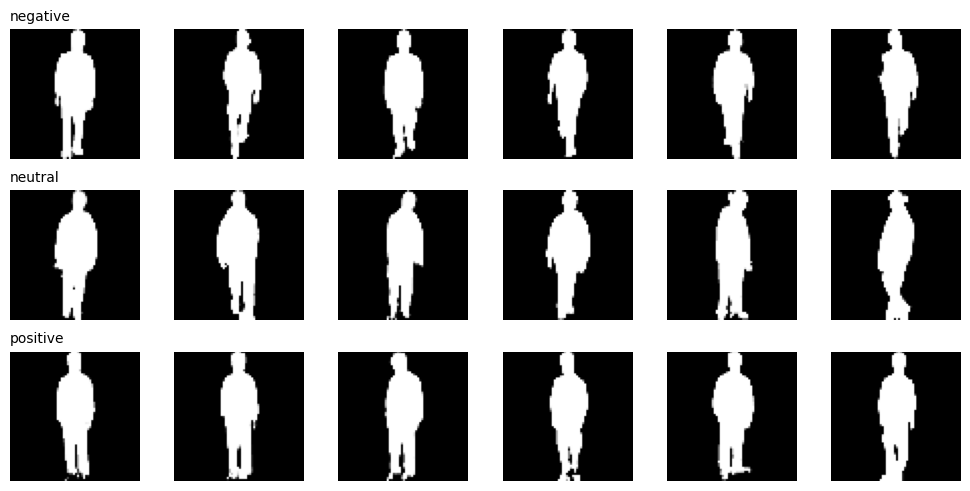

In [3]:
# A quick look: 6 evenly spaced frames from each sample
fig, axes = plt.subplots(len(LABELS), 6, figsize=(10, 5))
for row, name in enumerate(LABELS):
    seq = raw[name]
    for col, t in enumerate(np.linspace(0, len(seq) - 1, 6).round().astype(int)):
        axes[row, col].imshow(seq[t], cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Preprocessing

Two tiny functions:

- `cut_and_normalize` copies `BaseSilCuttingTransform`: a 64 px wide image loses 10 px on each side (so 64 to 44 wide), then values are divided by 255.
- `random_clip` picks `N_FRAMES` random frames from a sequence. Training uses this (`fixed_unordered` in your YAML). Frame order does not matter because temporal pooling is a max.

In [4]:
def cut_and_normalize(seq):
    """uint8 [T, H, W]  ->  float32 [T, H, W-20] in 0..1  (same as BaseSilCuttingTransform)."""
    cut = seq.shape[-1] // 64 * 10
    if cut > 0:
        seq = seq[..., cut:-cut]
    return seq.astype(np.float32) / 255.0

def random_clip(seq, n_frames=N_FRAMES):
    """Pick n_frames random frames (with repeats only if the video is shorter)."""
    idx = np.random.choice(len(seq), n_frames, replace=len(seq) < n_frames)
    return seq[idx]

def train_clip(seq, n_frames=N_FRAMES):
    return cut_and_normalize(random_clip(seq, n_frames))

clip = cut_and_normalize(random_clip(raw["positive"]))
print("clip shape:", clip.shape, "| range:", clip.min(), "to", clip.max())
assert clip.shape == (N_FRAMES, 64, 44)

clip shape: (30, 64, 44) | range: 0.0 to 1.0


## 4. Baseline CNN architecture

The paper specifies that Baseline CNN uses cross-entropy and excludes HPP and BNNeck. The backbone follows the `ResNet9` settings in the official OpenGait ScoNet YAML: one residual block per stage, channels 64 / 128 / 256 / 512, strides 1 / 2 / 2 / 1, and no max-pooling.

In [5]:
class BasicBlock(nn.Module):
    """conv-bn-relu-conv-bn, plus a skip connection."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:        # skip path must match the new shape
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)

class ResNet9(nn.Module):
    def __init__(self, in_channels=1, channels=(64, 128, 256, 512), strides=(1, 2, 2, 1)):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, channels[0], 3, 1, 1, bias=False),
            nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        blocks, prev = [], channels[0]
        for ch, stride in zip(channels, strides):
            blocks.append(BasicBlock(prev, ch, stride))
            prev = ch
        self.blocks = nn.Sequential(*blocks)

    def forward(self, x):              # [n, 1, h, w] -> [n, 512, h/4, w/4]
        return self.blocks(self.stem(x))

# test: 5 images of 64x44
print(ResNet9()(torch.randn(5, 1, 64, 44)).shape)   # expect [5, 512, 16, 11]

torch.Size([5, 512, 16, 11])


### 4.2 Run the backbone on every frame
ResNet9 expects ordinary images `[batch, 1, h, w]`, but we have videos `[n, 1, s, h, w]`. `FrameWise` folds the frames into the batch dimension, runs the backbone, and unfolds again.

In [6]:
class FrameWise(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, x):                                   # x: [n, c, s, h, w]
        n, c, s, h, w = x.shape
        x = x.permute(0, 2, 1, 3, 4).reshape(n * s, c, h, w)    # every frame becomes its own image
        out = self.net(x)                                       # [n*s, c', h', w']
        _, c2, h2, w2 = out.shape
        return out.reshape(n, s, c2, h2, w2).permute(0, 2, 1, 3, 4)   # [n, c', s, h', w']

test = FrameWise(ResNet9())(torch.randn(2, 1, 7, 64, 44))
print(test.shape)   # expect [2, 512, 7, 16, 11]

torch.Size([2, 512, 7, 16, 11])


### Baseline CNN head

The paper's Baseline CNN excludes horizontal pooling and BNNeck. After the same ResNet9 backbone and temporal max pooling used in the ScoNet configuration, this baseline globally averages the spatial feature map and classifies it with one linear layer. No triplet loss is used.

In [7]:
class BaselineCNN(nn.Module):
    """Baseline CNN: ResNet9 + temporal max pooling + spatial average pooling + linear classifier.

    No horizontal pooling, SeparateFCs, BNNeck, or triplet objective.
    Input: [batch, frames, 64, 44]
    Output shapes preserve the existing training/evaluation interface:
      embedding [batch, 512, 1], logits [batch, 3, 1]
    """
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.backbone = FrameWise(ResNet9())
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, sils):
        x = sils.unsqueeze(1)       # [n, 1, s, h, w]
        x = self.backbone(x)        # [n, 512, s, 16, 11]
        x = x.max(dim=2)[0]         # temporal max pooling: [n, 512, 16, 11]
        x = x.mean(dim=(2, 3))      # spatial global average pooling: [n, 512]
        logits = self.classifier(x) # [n, 3]
        return x.unsqueeze(-1), logits.unsqueeze(-1)  # compatible [n, c, 1] and [n, 3, 1]

def init_weights(m):
    """Use the same general initialization style as the OpenGait model code."""
    if isinstance(m, nn.Conv2d):
        nn.init.xavier_uniform_(m.weight)
    elif isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)) and m.affine:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

def make_model():
    model = BaselineCNN()
    model.apply(init_weights)
    return model.to(DEVICE)

model = make_model()
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

with torch.no_grad():
    embed, logits = model.eval()(torch.rand(2, N_FRAMES, 64, 44, device=DEVICE))
print("embed :", tuple(embed.shape), " expect (2, 512, 1)")
print("logits:", tuple(logits.shape), " expect (2, 3, 1)")
assert embed.shape == (2, 512, 1) and logits.shape == (2, 3, 1)

Parameters: 4.90M
embed : (2, 512, 1)  expect (2, 512, 1)
logits: (2, 3, 1)  expect (2, 3, 1)


### Baseline model ready

## 5. Loss

The paper's **Baseline CNN uses cross-entropy only**. There is no triplet loss for this model.

In [8]:
def scaled_ce_loss(logits, classes, scale=CE_SCALE, label_smoothing=0.0):
    """Ordinary cross-entropy for baseline logits [batch, classes, 1]."""
    logits = logits.mean(-1)  # [batch, classes]
    return F.cross_entropy(logits * scale, classes, label_smoothing=label_smoothing)

# quick shape/loss check
test_logits = torch.randn(6, NUM_CLASSES, 1)
test_classes = torch.tensor([0, 0, 1, 1, 2, 2])
print("baseline CE:", float(scaled_ce_loss(test_logits, test_classes)))

baseline CE: 1.3874722719192505


## 6. Training loop

The baseline is trained with cross-entropy only. The optimizer and schedule follow the paper/OpenGait ScoNet configuration: SGD, LR 0.1, momentum 0.9, weight decay 0.0005, and learning-rate drops at 10k / 14k / 18k iterations.

In [9]:
def compute_loss(embed, logits, ids, classes, triplet_on=None, label_smoothing=0.0):
    """Baseline CNN objective: cross-entropy only; triplet loss is intentionally disabled."""
    loss_ce = scaled_ce_loss(logits, classes, label_smoothing=label_smoothing)
    return loss_ce, loss_ce, torch.zeros((), device=DEVICE)

def save_checkpoint(path, model, optimizer, scheduler, scaler, it, history):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "iter": it, "history": history}, path)

def load_checkpoint(path, model, optimizer, scheduler, scaler):
    """Restore checkpoint. Returns (history, next iteration)."""
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    print(f"resumed from {path} at iteration {ckpt['iter']}")
    return ckpt["history"], ckpt["iter"] + 1

def train(model, get_batch, iters, lr=0.1, milestones=(), log_every=10,
          triplet_on=None, amp=False, label_smoothing=0.0,
          ckpt_path=None, save_every=0, resume=False):
    """Train Baseline CNN using cross-entropy only."""
    amp = amp and DEVICE.type == "cuda"
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(milestones), gamma=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    history = {"triplet": [], "ce": [], "acc": []}
    start_it = 1

    if resume and ckpt_path and Path(ckpt_path).is_file():
        history, start_it = load_checkpoint(ckpt_path, model, optimizer, scheduler, scaler)

    t0 = time.time()
    for it in range(start_it, iters + 1):
        model.train()
        sils, ids, classes = get_batch()
        sils = torch.as_tensor(sils, dtype=torch.float32, device=DEVICE)
        classes = torch.as_tensor(classes, dtype=torch.long, device=DEVICE)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
            embed, logits = model(sils)
        logits = logits.float()
        loss, loss_ce, loss_tri = compute_loss(embed, logits, None, classes, label_smoothing=label_smoothing)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        acc = (logits.mean(-1).argmax(1) == classes).float().mean().item()
        history["triplet"].append(0.0)
        history["ce"].append(loss_ce.item())
        history["acc"].append(acc)

        if it == start_it or it % log_every == 0:
            elapsed = time.time() - t0
            eta = elapsed / (it - start_it + 1) * (iters - it)
            print(f"iter {it:5d} | CE {loss_ce.item():.4f} | acc {acc:.2f}"
                  f" | {elapsed / 60:6.1f} min elapsed, ETA {eta / 60:6.1f} min")
        if ckpt_path and save_every and (it % save_every == 0 or it == iters):
            save_checkpoint(ckpt_path, model, optimizer, scheduler, scaler, it, history)
    return history

def plot_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(history["ce"], label="cross-entropy")
    ax[0].set_xlabel("iteration"); ax[0].set_title("training loss"); ax[0].legend()
    ax[1].plot(history["acc"]); ax[1].set_xlabel("iteration"); ax[1].set_title("train accuracy"); ax[1].set_ylim(0, 1.05)
    plt.tight_layout(); plt.show()

For evaluation, the whole sequence (up to 720 frames) is passed through the model. The baseline produces one three-class score vector per sequence.

In [10]:
@torch.no_grad()
def predict(model, seq_uint8, max_frames=720):
    """One raw sequence [T, 64, 64] -> (predicted class id, class probabilities)."""
    model.eval()
    seq_uint8 = seq_uint8[:max_frames]       # OpenGait (collate_fn.py) keeps the first frames_all_limit frames
    x = torch.from_numpy(cut_and_normalize(seq_uint8)).unsqueeze(0).to(DEVICE)    # [1, T, 64, 44]
    _, logits = model(x)                                                           # [1, 3, 1]
    scores = logits.mean(-1)                                                       # [1, 3]
    probs = torch.softmax(scores * CE_SCALE, dim=-1)[0].cpu().numpy()
    return int(probs.argmax()), probs

## 7. Sanity check: can the baseline learn?

This small check trains on a few clips from one sample per class. It verifies that the baseline model, loss, and prediction path work end-to-end. It is **not** a paper result.

In [11]:
if DEVICE.type == "cuda":
    SANITY_FRAMES, K_CLIPS, SANITY_ITERS, EVAL_MAX_FRAMES = N_FRAMES, 2, 20, 60 #Original sanity test: N_FRAMES, 4, 100, 720
else:                                   # CPU: smaller and slower-to-fail setup
    SANITY_FRAMES, K_CLIPS, SANITY_ITERS, EVAL_MAX_FRAMES = 8, 2, 60, 100
SANITY_LR = 0.1                         # lower to 0.01 if the loss jumps around

def get_sanity_batch():
    clips, ids, classes = [], [], []
    for class_id, name in enumerate(LABELS):
        for _ in range(K_CLIPS):
            clips.append(train_clip(raw[name], SANITY_FRAMES))
            ids.append(class_id)          # unused by the CE-only baseline
            classes.append(class_id)
    return np.stack(clips), np.array(ids), np.array(classes)

sils, ids, classes = get_sanity_batch()
print("batch silhouettes:", sils.shape, "| ids:", ids, "| classes:", classes)

batch silhouettes: (6, 30, 64, 44) | ids: [0 0 1 1 2 2] | classes: [0 0 1 1 2 2]


iter     1 | CE 1.1814 | acc 0.33 |    0.1 min elapsed, ETA    2.0 min
iter    10 | CE 1.6173 | acc 0.33 |    0.2 min elapsed, ETA    0.2 min
iter    20 | CE 1.1903 | acc 0.33 |    0.3 min elapsed, ETA    0.0 min


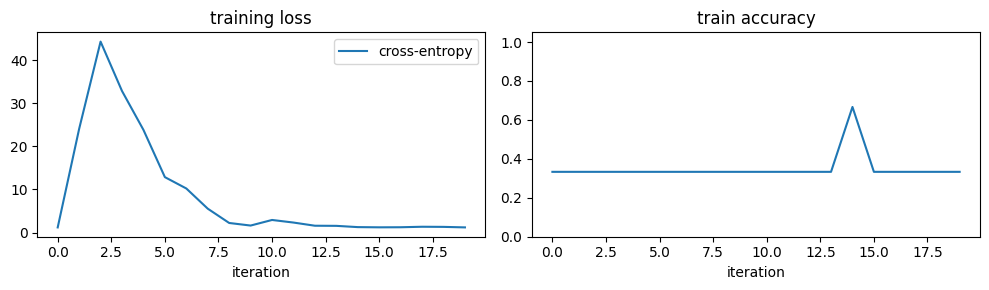

In [12]:
set_seed()                                  # same start every time
sanity_model = make_model()
history = train(sanity_model, get_sanity_batch, iters=SANITY_ITERS, lr=SANITY_LR, log_every=10, milestones=(), label_smoothing=0.0)
plot_history(history)

In [13]:
ce_start, ce_end = np.mean(history["ce"][:3]), np.mean(history["ce"][-5:])
acc_end = np.mean(history["acc"][-5:])
print(f"cross-entropy: {ce_start:.3f} -> {ce_end:.3f}")
print(f"train accuracy (last 5 iters): {acc_end:.2f}")
print("TRAINING CHECK:", "PASS" if (ce_end < 0.5 * ce_start and acc_end >= 0.99) else "FAIL - see notes below")

cross-entropy: 23.202 -> 1.254
train accuracy (last 5 iters): 0.33
TRAINING CHECK: FAIL - see notes below


Now the evaluation path: whole video in, prediction out. The same three videos are used, so this only proves the eval code works.

In [14]:
correct = 0
for class_id, name in enumerate(LABELS):
    pred, probs = predict(sanity_model, raw[name], EVAL_MAX_FRAMES)
    correct += int(pred == class_id)
    print(f"true {name:9s} -> predicted {LABELS[pred]:9s} probs (neg, neu, pos) = {np.round(probs, 3)}")
print(f"\nEVAL CHECK: {correct}/3 correct")

true negative  -> predicted negative  probs (neg, neu, pos) = [1. 0. 0.]
true neutral   -> predicted negative  probs (neg, neu, pos) = [1. 0. 0.]
true positive  -> predicted negative  probs (neg, neu, pos) = [1. 0. 0.]

EVAL CHECK: 1/3 correct


## 8. Train and evaluate Baseline CNN with the paper's protocol

The full run uses the same partition JSON and subject-based batch construction as the existing notebook. For a paper-budget run, select `PROFILE = "paper"` (20,000 iterations, 8 identities × 8 sequences) and use `ONE_PER_CLASS = False`.

In [15]:
# ================= protocol settings =================
RUN_FULL = True
PARTITION_JSON = Path(r"c:/Users/arina/OneDrive/Documents/Reproduce_Paper/OpenGait/datasets/Scoliosis1K/Scoliosis1K_118.json")  # paper main setting: 1:1:8
ONE_PER_CLASS = True       # False = use the full training split; True is only for a tiny debug run

MODEL_VARIANT = "BaselineCNN"
PROFILE = "test"          # paper: 20,000 iterations, 8 identities x 8 sequences
PROFILES = {
    "quick":  dict(iters=200,   ids=4, seqs=4),
    "scaled": dict(iters=2000,  ids=8, seqs=4),
    "test":   dict(iters=5000,  ids=4, seqs=4),
    "paper":  dict(iters=20000, ids=8, seqs=8),
}
TOTAL_ITERS = PROFILES[PROFILE]["iters"]
IDS_PER_BATCH = PROFILES[PROFILE]["ids"]
SEQS_PER_ID = PROFILES[PROFILE]["seqs"]
FULL_EVAL_FRAMES = 720

USE_AMP = DEVICE.type == "cuda"   # OpenGait YAML: enable_float16 = true
LABEL_SMOOTHING = 0.0             # plain CE baseline; no triplet or cosine BNNeck head
LOG_EVERY = 100 if TOTAL_ITERS > 2000 else 20
SAVE_EVERY = 5000 if TOTAL_ITERS >= 20000 else 500
RESUME = False
CKPT_PATH = f"baseline_cnn_{PROFILE}.pt"  # separate checkpoint from all ScoNet experiments
EVAL_EVERY = max(TOTAL_ITERS // 4, 1)
EVAL_PER_CLASS = 30

# Paper's reported Baseline CNN result (Table 3, not a target/guarantee)
PAPER_BASELINE_CNN = (45.5, 99.0, 27.0)  # accuracy, sensitivity, specificity as reported in the paper
SPLIT_KEY = PARTITION_JSON.stem.split("_")[-1]
PAPER_SPLITS = {"112": (186, 186, 373), "114": (124, 124, 497),
                "118": (74, 74, 596), "1116": (41, 41, 663)}

In [16]:
@lru_cache(maxsize=None)
def load_pkl_cached(path):
    """Load each pkl only once (the same videos are used again and again)."""
    return load_pkl(path)

def build_index(root, subject_ids):
    """List (subject_id, class_id, pkl_path) for every sequence of the given subjects."""
    items, missing = [], 0
    for sid in subject_ids:
        folder = root / str(sid)
        if not folder.is_dir():
            missing += 1
            continue
        for pkl in sorted(folder.rglob("*.pkl")):
            names = [p.lower() for p in pkl.relative_to(root).parts[:-1]]
            class_id = next((LABEL_TO_ID[n] for n in names if n in LABEL_TO_ID), None)
            if class_id is not None:
                items.append((str(sid), class_id, pkl))
    print(f"{len(items)} sequences from {len(set(i[0] for i in items))} subjects ({missing} listed subjects not on disk)")
    return items

def make_triplet_batch_fn(items, ids_per_batch, seqs_per_id):
    """Batches like OpenGait's TripletSampler (checked in sampler.py): `ids_per_batch` random subjects without replacement,
    `seqs_per_id` sequences of each (repeated only if the subject has fewer)."""
    by_subject = {}
    for sid, class_id, path in items:
        by_subject.setdefault(sid, []).append((class_id, path))
    subjects = list(by_subject)
    index = {sid: i for i, sid in enumerate(subjects)}          # subject id (string) -> integer id for the loss

    def get_batch():
        clips, ids, classes = [], [], []
        for sid in random.sample(subjects, min(ids_per_batch, len(subjects))):
            pool = by_subject[sid]
            if len(pool) >= seqs_per_id:
                picks = random.sample(pool, seqs_per_id)        # different sequences of this subject
            else:
                picks = random.choices(pool, k=seqs_per_id)     # too few sequences: repeat (new random frames each time)
            for class_id, path in picks:
                clips.append(train_clip(load_pkl_cached(path)))
                ids.append(index[sid])
                classes.append(class_id)
        return np.stack(clips), np.array(ids), np.array(classes)
    return get_batch

def class_counts(items):
    counts = [0, 0, 0]                       # negative, neutral, positive
    for _, class_id, _ in items:
        counts[class_id] += 1
    return counts

def select_one_per_class(items):
    """Keep only the first sequence of each class (negative, neutral, positive) -> 3 sequences. Fixed: no randomness involved."""
    selected = {}
    for item in items:
        _, class_id, _ = item
        if class_id not in selected:
            selected[class_id] = item
    return [selected[c] for c in sorted(selected)]

def check_split(train_items, test_items):
    """Print the class counts next to the paper's, to confirm the partition is the one you meant."""
    tr, te = class_counts(train_items), class_counts(test_items)
    total = max(sum(tr), 1)
    pos = max(tr[2], 1)
    print(f"train: negative {tr[0]} | neutral {tr[1]} | positive {tr[2]}   (positive:neutral:negative = 1:{tr[1] / pos:.1f}:{tr[0] / pos:.1f})")
    print(f"test : negative {te[0]} | neutral {te[1]} | positive {te[2]}")
    if SPLIT_KEY in PAPER_SPLITS:
        p, n, g = PAPER_SPLITS[SPLIT_KEY]
        print(f"paper, split {SPLIT_KEY}: train positive {p} | neutral {n} | negative {g}")
    p_pos = tr[2] / total
    print(f"negative is {tr[0] / total:.0%} of the training set; a batch of {IDS_PER_BATCH} identities "
          f"contains no positive in {(1 - p_pos) ** IDS_PER_BATCH:.0%} of iterations")

def make_eval_subset(test_items, per_class=EVAL_PER_CLASS):
    """A small test subset used for the quick checks during training. Always the same videos (own seed 0)."""
    rng = random.Random(0)
    subset = []
    for c in range(3):
        pool = [it for it in test_items if it[1] == c]
        subset += rng.sample(pool, min(per_class, len(pool)))
    return subset

In [17]:
def confusion(model, items, max_frames=FULL_EVAL_FRAMES):
    """rows = true, cols = predicted (negative, neutral, positive); the whole video (up to max_frames) per sequence."""
    conf = np.zeros((3, 3), dtype=int)
    for _, class_id, path in items:
        pred, _ = predict(model, load_pkl_cached(path), max_frames)
        conf[class_id, pred] += 1
    return conf

def paper_metrics(conf):
    """accuracy, sensitivity, specificity as the numbers in the paper's Table 2 and Fig. 4 work out.
    Derived from Fig. 4: the paper's text definitions look swapped, and OpenGait's evaluate_scoliosis does not
    compute sensitivity / specificity at all (it logs accuracy and the macro precision / recall / F1, see macro_metrics)."""
    accuracy = conf.trace() / max(conf.sum(), 1)
    sensitivity = conf[0, 0] / max(conf[0].sum(), 1)                 # negatives predicted negative
    specificity = conf[1:, 1:].sum() / max(conf[1:].sum(), 1)        # neutral + positive predicted as neutral or positive
    return accuracy, sensitivity, specificity

def macro_metrics(conf):
    """Macro-averaged precision, recall and F1, as OpenGait's evaluate_scoliosis logs them (zero_division = 0)."""
    recall = conf.diagonal() / np.maximum(conf.sum(1), 1)
    precision = conf.diagonal() / np.maximum(conf.sum(0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)
    return precision.mean(), recall.mean(), f1.mean()

def evaluate(model, items, max_frames=FULL_EVAL_FRAMES):
    """Full report: confusion matrix and per-class metrics."""
    conf = confusion(model, items, max_frames)
    accuracy, sensitivity, specificity = paper_metrics(conf)
    print("confusion matrix (rows = true, cols = predicted; order: negative, neutral, positive)")
    print(conf)
    print(f"predicted per class: negative {conf[:, 0].sum()} | neutral {conf[:, 1].sum()} | positive {conf[:, 2].sum()}")
    print(f"accuracy {accuracy:.1%} | sensitivity {sensitivity:.1%} | specificity {specificity:.1%}")
    macro_p, macro_r, macro_f1 = macro_metrics(conf)
    print(f"macro precision {macro_p:.1%} | macro recall {macro_r:.1%} | macro F1 {macro_f1:.1%}")
    for k, name in enumerate(LABELS):
        recall = conf[k, k] / max(conf[k].sum(), 1)
        precision = conf[k, k] / max(conf[:, k].sum(), 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-9)
        print(f"  {name:9s} precision {precision:.3f}  recall {recall:.3f}  f1 {f1:.3f}")
    a, se, sp = PAPER_BASELINE_CNN
    print(f"\\nPaper Baseline CNN reference (Table 3): accuracy {a}% | sensitivity {se}% | specificity {sp}%")
    return conf

def train_with_periodic_eval(model, get_batch, eval_subset, triplet_on):
    """Train in chunks of EVAL_EVERY iterations and test the small subset after each chunk."""
    milestones = [m for m in (10000, 14000, 18000) if m < TOTAL_ITERS]  # exact paper milestones; shorter profiles may have none
    train_kwargs = dict(lr=0.1, milestones=milestones, log_every=LOG_EVERY, triplet_on=triplet_on, amp=USE_AMP,
                        label_smoothing=LABEL_SMOOTHING, ckpt_path=CKPT_PATH, save_every=SAVE_EVERY)

    if EVAL_EVERY and EVAL_EVERY < TOTAL_ITERS:
        stops = list(range(EVAL_EVERY, TOTAL_ITERS, EVAL_EVERY)) + [TOTAL_ITERS]
    else:
        stops = [TOTAL_ITERS]

    eval_iters, eval_acc, eval_recall = [], [], []
    for k, stop in enumerate(stops):
        history = train(model, get_batch, iters=stop, resume=(RESUME if k == 0 else True), **train_kwargs)
        sub = confusion(model, eval_subset)
        eval_iters.append(stop)
        eval_acc.append(sub.trace() / max(sub.sum(), 1))
        eval_recall.append(sub.diagonal() / np.maximum(sub.sum(1), 1))
        print(f"  -> iteration {stop}: test-subset accuracy {eval_acc[-1]:.2f} | recall neg/neu/pos "
              f"{eval_recall[-1][0]:.2f} / {eval_recall[-1][1]:.2f} / {eval_recall[-1][2]:.2f}\n")
    return history, eval_iters, eval_acc, eval_recall

def plot_results(history, eval_iters, eval_acc, eval_recall, conf, triplet_on):
    """Three panels: training loss, accuracy curves, and the test confusion matrix."""
    accuracy, sensitivity, specificity = paper_metrics(conf)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

    # 1) loss
    ax[0].plot(history["ce"], label="cross-entropy", alpha=0.85)
    ax[0].set_title("training loss"); ax[0].set_xlabel("iteration"); ax[0].legend()

    # 2) accuracy curves
    train_acc = np.array(history["acc"])
    win = max(1, min(20, len(train_acc) // 5))
    ax[1].plot(train_acc, color="tab:blue", alpha=0.2, label="train batch accuracy")
    if len(train_acc) >= win:
        smooth = np.convolve(train_acc, np.ones(win) / win, mode="valid")
        ax[1].plot(range(win - 1, len(train_acc)), smooth, color="tab:blue", label=f"train, moving average ({win})")
    recalls = np.array(eval_recall)
    ax[1].plot(eval_iters, eval_acc, "o-", color="black", linewidth=2, label="test accuracy (subset)")
    for k, name in enumerate(LABELS):
        ax[1].plot(eval_iters, recalls[:, k], "--", marker=".", label=f"test recall: {name}")
    ax[1].set_title("accuracy"); ax[1].set_xlabel("iteration"); ax[1].set_ylim(0, 1.05)
    ax[1].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))

    # 3) confusion matrix (colour = share of each true class, text = count and share)
    norm = conf / np.maximum(conf.sum(1, keepdims=True), 1)
    im = ax[2].imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax[2].text(j, i, f"{conf[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center",
                       color="white" if norm[i, j] > 0.5 else "black")
    ax[2].set_xticks(range(3)); ax[2].set_xticklabels(LABELS)
    ax[2].set_yticks(range(3)); ax[2].set_yticklabels(LABELS)
    ax[2].set_xlabel("predicted"); ax[2].set_ylabel("true")
    ax[2].set_title(f"test confusion matrix (n={conf.sum()})")
    fig.colorbar(im, ax=ax[2], fraction=0.046)

    fig.suptitle(f"{MODEL_VARIANT} | {PROFILE}: {TOTAL_ITERS} iterations, {IDS_PER_BATCH}x{SEQS_PER_ID} batch | "
                 f"test accuracy {accuracy:.1%}, sensitivity {sensitivity:.1%}, specificity {specificity:.1%}", y=1.03)
    plt.tight_layout(); plt.show()

In [18]:
if not RUN_FULL:
    print("RUN_FULL is False -> skipping. Set it to True above to train on the partition.")
else:
    # ---------- data ----------
    with open(PARTITION_JSON, "r", encoding="utf-8") as f:
        partition = json.load(f)

    train_items = build_index(DATASET_ROOT, partition["TRAIN_SET"])
    test_items = build_index(DATASET_ROOT, partition["TEST_SET"])

    print("Training samples:", len(train_items))
    print("Class counts:", class_counts(train_items))

    check_split(train_items, test_items)

    if ONE_PER_CLASS:
        train_items = select_one_per_class(train_items)
        print("\nONE_PER_CLASS: training on only " + str(len(train_items)) + " sequences (the first of each class): "
              + ", ".join(f"{LABELS[c]} (subject {sid})" for sid, c, _ in train_items))
    ids_in_batch = min(IDS_PER_BATCH, len({sid for sid, _, _ in train_items}))      # fewer subjects than IDS_PER_BATCH -> smaller batch

    if DEVICE.type == "cuda":
        print(f"\nGPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB) | float16: {USE_AMP}")
    print(f"{MODEL_VARIANT} | profile '{PROFILE}': {TOTAL_ITERS} iterations, {ids_in_batch} ids x {SEQS_PER_ID} clips "
          f"= {ids_in_batch * SEQS_PER_ID} sequences per iteration\n")

    # ---------- training (in chunks, with a quick test-subset check after each chunk) ----------
    set_seed()                                       # same start every time, whatever cells ran before
    eval_subset = make_eval_subset(test_items)
    triplet_on = None  # Baseline CNN is CE-only
    full_model = make_model()
    get_batch = make_triplet_batch_fn(train_items, IDS_PER_BATCH, SEQS_PER_ID)
    history_full, eval_iters, eval_acc, eval_recall = train_with_periodic_eval(full_model, get_batch, eval_subset, triplet_on)

    # ---------- final evaluation on the whole test set ----------
    print("Evaluating on the whole TEST_SET ...")
    conf = confusion(full_model, test_items)
    accuracy, sensitivity, specificity = paper_metrics(conf)
    print(f"accuracy {accuracy:.1%} | sensitivity {sensitivity:.1%} | specificity {specificity:.1%}")
    print(f"paper Baseline CNN reference (Table 3): accuracy {PAPER_BASELINE_CNN[0]}% | sensitivity {PAPER_BASELINE_CNN[1]}% | specificity {PAPER_BASELINE_CNN[2]}%")
    macro_p, macro_r, macro_f1 = macro_metrics(conf)
    print(f"macro precision {macro_p:.1%} | macro recall {macro_r:.1%} | macro F1 {macro_f1:.1%}   (what OpenGait's evaluate_scoliosis logs)")

    plot_results(history_full, eval_iters, eval_acc, eval_recall, conf, triplet_on)

744 sequences from 744 subjects (0 listed subjects not on disk)
749 sequences from 749 subjects (0 listed subjects not on disk)
Training samples: 744
Class counts: [596, 74, 74]
train: negative 596 | neutral 74 | positive 74   (positive:neutral:negative = 1:1.0:8.1)
test : negative 204 | neutral 126 | positive 419
paper, split 118: train positive 74 | neutral 74 | negative 596
negative is 80% of the training set; a batch of 4 identities contains no positive in 66% of iterations

ONE_PER_CLASS: training on only 3 sequences (the first of each class): negative (subject 01028), neutral (subject 01482), positive (subject 00196)

GPU: NVIDIA RTX A2000 Laptop GPU (4.3 GB) | float16: True
BaselineCNN | profile 'test': 5000 iterations, 3 ids x 4 clips = 12 sequences per iteration

iter     1 | CE 1.1172 | acc 0.33 |    0.0 min elapsed, ETA   39.1 min
iter   100 | CE 0.4196 | acc 0.83 |    1.3 min elapsed, ETA   14.4 min
iter   200 | CE 0.3985 | acc 0.67 |    3.0 min elapsed, ETA   15.6 min
iter

KeyboardInterrupt: 

## Notes

- This notebook trains **Baseline CNN only** with cross-entropy; no horizontal pooling, SeparateFCs, BNNeck, or triplet loss is active.
- For a quick pipeline check use `PROFILE = "quick"`. For the paper training budget use `PROFILE = "paper"`, `ONE_PER_CLASS = False`, and the correct `Scoliosis1K_118.json` partition.
- The paper's reported Baseline CNN result is 45.5% accuracy (Table 3). Your result can differ because the paper does not fully specify the baseline's internal layer/head details beyond excluding HPP and BNNeck.
- The linked OpenGait `baseline.py` includes HPP and SeparateBNNecks, so copying that full model would conflict with the paper's Baseline CNN description. This notebook reuses the OpenGait ScoNet YAML's ResNet9 backbone configuration and omits those components as required by the paper.